# Week 1 Assignment 1: Neural Network Foundations & PyTorch

**Skill Nexis — Deep Learning Internship**

## Objectives
In this notebook, we will (1) understand key neural-network terms, (2) practice PyTorch tensors, (3) train a small model on synthetic regression data, (4) plot training and validation loss, and (5) compare two learning rates.

Run the cells from top to bottom. This assignment is separate from the MNIST Digit Recognizer in the `Mini-project` folder.

## Task 1 — Important concepts

- **Neuron:** a small computation unit that combines inputs and produces an output.
- **Weight:** a trainable value that controls the strength of an input.
- **Bias:** a trainable value added to the weighted sum, allowing the output to shift.
- **Epoch:** one full pass through all training examples.
- **Batch:** a smaller group of examples processed together.
- **Learning rate:** controls how large each optimizer update is. Too high can make training unstable; too low can make it slow.

## Task 2 — PyTorch tensor operations

In [1]:
import torch
import torch.nn as nn
import matplotlib.pyplot as plt

torch.manual_seed(42)
print("PyTorch version:", torch.__version__)

PyTorch version: 2.14.1+cpu


In [2]:
# Create tensors
a = torch.tensor([[1, 2, 3], [4, 5, 6]], dtype=torch.float32)
b = torch.tensor([[10, 20, 30], [40, 50, 60]], dtype=torch.float32)
print("Tensor a:\n", a)
print("Shape:", a.shape)

# Reshape a 1-D tensor into 2 rows and 3 columns
x = torch.arange(6)
print("Reshaped tensor:\n", x.reshape(2, 3))

# Element-wise multiplication and matrix multiplication
print("Element-wise multiplication:\n", a * b)
print("Matrix multiplication (a @ b.T):\n", a @ b.T)

# Indexing
print("First row:", a[0])
print("Value at row 2, column 3:", a[1, 2].item())

Tensor a:
 tensor([[1., 2., 3.],
        [4., 5., 6.]])
Shape: torch.Size([2, 3])
Reshaped tensor:
 tensor([[0, 1, 2],
        [3, 4, 5]])
Element-wise multiplication:
 tensor([[ 10.,  40.,  90.],
        [160., 250., 360.]])
Matrix multiplication (a @ b.T):
 tensor([[140., 320.],
        [320., 770.]])
First row: tensor([1., 2., 3.])
Value at row 2, column 3: 6.0


## Task 3 — Train a model on synthetic regression data

We will generate data following approximately `y = 3x + 2`, split it into training, validation, and test sets, and train a small linear model with PyTorch. Validation data helps us monitor performance on examples not used for weight updates.

In [3]:
# Generate a reproducible synthetic dataset
torch.manual_seed(42)
X = torch.linspace(-5, 5, 200).reshape(-1, 1)
y = 3 * X + 2 + 0.5 * torch.randn_like(X)

# Shuffle before splitting
indices = torch.randperm(len(X))
X, y = X[indices], y[indices]
X_train, y_train = X[:140], y[:140]
X_val, y_val = X[140:170], y[140:170]
X_test, y_test = X[170:], y[170:]

print("Training examples:", len(X_train))
print("Validation examples:", len(X_val))
print("Test examples:", len(X_test))

# Define a simple one-layer neural network
model = nn.Linear(1, 1)
criterion = nn.MSELoss()
optimizer = torch.optim.SGD(model.parameters(), lr=0.01)

train_losses, val_losses = [], []
epochs = 100
for epoch in range(epochs):
    model.train()
    optimizer.zero_grad()
    predictions = model(X_train)
    train_loss = criterion(predictions, y_train)
    train_loss.backward()  # backpropagation computes gradients
    optimizer.step()       # gradient descent updates weights and bias

    model.eval()
    with torch.no_grad():
        val_loss = criterion(model(X_val), y_val)
    train_losses.append(train_loss.item())
    val_losses.append(val_loss.item())

print("Final training loss:", round(train_losses[-1], 4))
print("Final validation loss:", round(val_losses[-1], 4))
print("Learned weight:", round(model.weight.item(), 3))
print("Learned bias:", round(model.bias.item(), 3))

Training examples: 140
Validation examples: 30
Test examples: 30
Final training loss: 0.3377
Final validation loss: 0.4262
Learned weight: 3.0
Learned bias: 1.683


## Task 4 — Plot training and validation loss

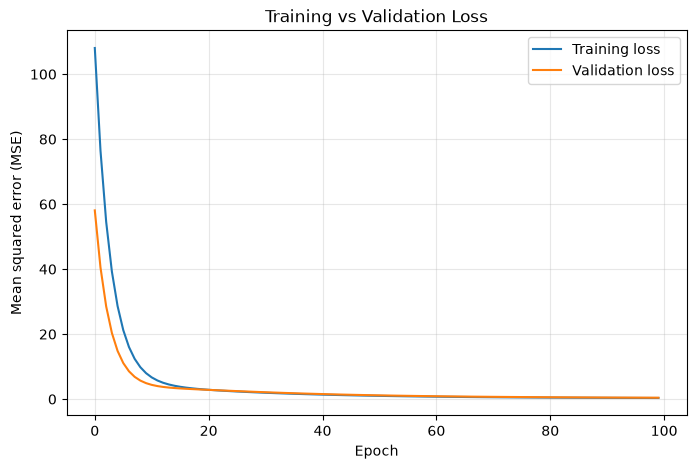

In [4]:
plt.figure(figsize=(8, 5))
plt.plot(train_losses, label="Training loss")
plt.plot(val_losses, label="Validation loss")
plt.xlabel("Epoch")
plt.ylabel("Mean squared error (MSE)")
plt.title("Training vs Validation Loss")
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

Test MSE: 0.3898


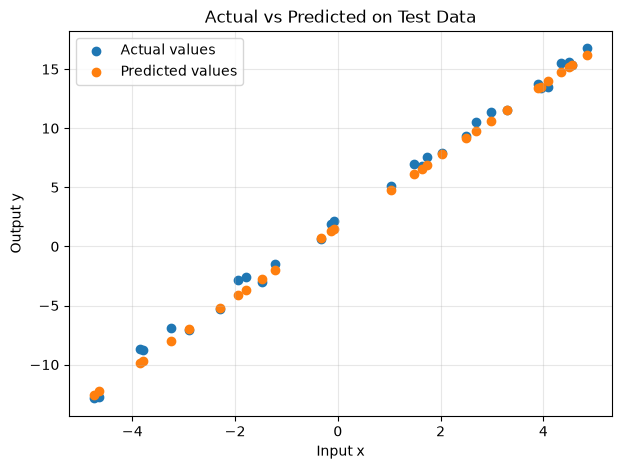

In [5]:
# Evaluate once on the held-out test set
model.eval()
with torch.no_grad():
    test_predictions = model(X_test)
    test_loss = criterion(test_predictions, y_test).item()
print("Test MSE:", round(test_loss, 4))

plt.figure(figsize=(7, 5))
plt.scatter(X_test.numpy(), y_test.numpy(), label="Actual values")
plt.scatter(X_test.numpy(), test_predictions.numpy(), label="Predicted values")
plt.xlabel("Input x")
plt.ylabel("Output y")
plt.title("Actual vs Predicted on Test Data")
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

## Task 5 — Compare two learning rates

We train the same model twice using learning rates `0.001` and `0.05`. The data split is kept the same so the comparison is fair. Lower validation loss is generally better, as long as training is stable.

In [6]:
def train_with_lr(learning_rate, epochs=100):
    torch.manual_seed(7)
    candidate = nn.Linear(1, 1)
    loss_fn = nn.MSELoss()
    opt = torch.optim.SGD(candidate.parameters(), lr=learning_rate)
    train_curve, val_curve = [], []

    for _ in range(epochs):
        candidate.train()
        opt.zero_grad()
        loss = loss_fn(candidate(X_train), y_train)
        loss.backward()
        opt.step()
        candidate.eval()
        with torch.no_grad():
            val = loss_fn(candidate(X_val), y_val)
        train_curve.append(loss.item())
        val_curve.append(val.item())
    return candidate, train_curve, val_curve

learning_rates = [0.001, 0.05]
results = {}
for lr in learning_rates:
    results[lr] = train_with_lr(lr)
    print(f"Learning rate {lr}: final train loss={results[lr][1][-1]:.4f}, "
          f"final validation loss={results[lr][2][-1]:.4f}")

Learning rate 0.001: final train loss=7.3039, final validation loss=5.4118
Learning rate 0.05: final train loss=0.2323, final validation loss=0.2717


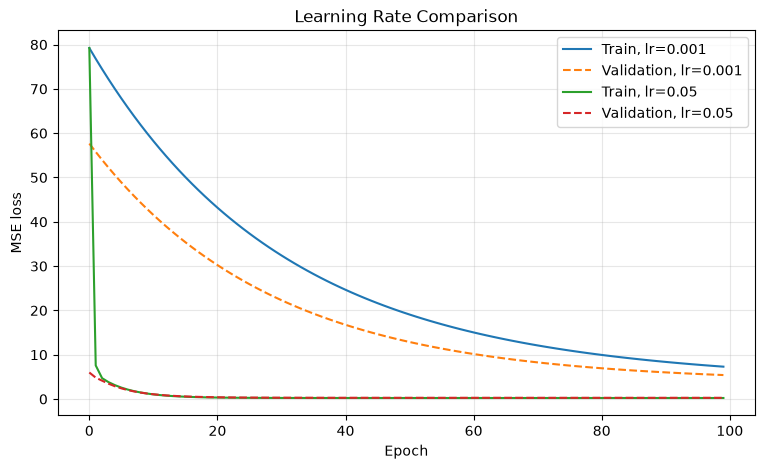

Lower final validation loss in this run: 0.05


In [7]:
plt.figure(figsize=(9, 5))
for lr in learning_rates:
    _, train_curve, val_curve = results[lr]
    plt.plot(train_curve, label=f"Train, lr={lr}")
    plt.plot(val_curve, linestyle="--", label=f"Validation, lr={lr}")
plt.xlabel("Epoch")
plt.ylabel("MSE loss")
plt.title("Learning Rate Comparison")
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

best_lr = min(learning_rates, key=lambda lr: results[lr][2][-1])
print("Lower final validation loss in this run:", best_lr)

## Short conclusion

Write your observations after running the notebook:

1. What do the weight and bias represent in this regression model?
2. Does the training loss decrease as epochs increase?
3. Which learning rate produced the lower final validation loss in your run?
4. Why do we keep a separate test set?

**Reminder:** The MNIST handwritten Digit Recognizer web application is the Week 1 Mini-project and is kept separately in `../Mini-project/`.